## Module 3: Computational Drug Discovery Project

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity (BMI ≥ 30) affects 40.3% of U.S. adults [1] and about 1 in 7 people worldwide [2]. It raises the risk of type 2 diabetes, heart, liver, and kidney disease, and several cancers [2]. Two gut hormones, GLP-1 and GIP, act on multiple organs to regulate appetite and metabolism. GLP-1 reduces food intake in the brain, slows gastric emptying, lowers glucagon, and raises cAMP in pancreatic beta cells to stimulate insulin release. GIP also raises insulin but promotes fat storage [3]. Modern treatments include semaglutide (sold as Ozempic and Wegovy), which mimics GLP-1 by activating its receptor, and tirzepatide, which activates both receptors [4]. Weekly semaglutide injections produced 14.9% weight loss over 68 weeks [5], and a daily pill was approved in December 2025 [6]. Yet obesity is chronic, as patients regained 2/3 of their lost weight within a year of stopping semaglutide [7], and U.S. adults who stopped GLP-1 drugs most often cited cost (36%) and side effects (33%) [8]. Patients therefore need more effective drugs that are easier to stay on. Retatrutide, which activates GLP-1, GIP, and glucagon receptors, reached 25.0% weight loss at 80 weeks in phase 3 [9], and once-monthly MariTide may improve adherence [10].

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


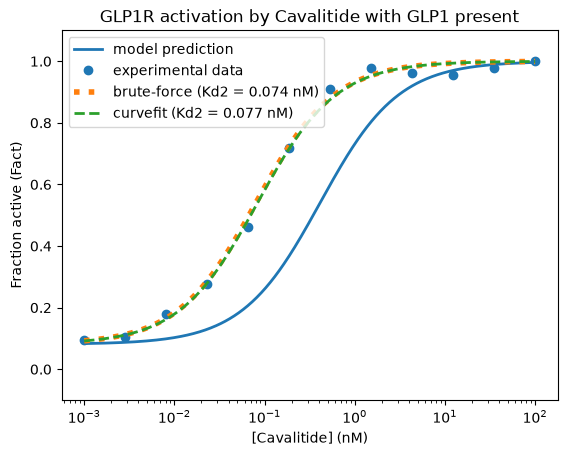

In [5]:
# fit_semaglutide_GLP1R.py
# 1a and 1b
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, semaglutide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
# I changed the file name to load the Cavalitide data instead of the semaglutide data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=4,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)") # I changed this from semaglutide to Cavalitide
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present") # I changed this from semaglutide to Cavalitide
plt.legend(loc="upper left")
plt.show()

1c: The fitted Kd value of Cavalitide is 0.077 nM. The Kd of semaglutide is 0.38 nM, so Cavalitide binds GLP1R about 5 times more tightly. Cavalitide also binds more tightly than native GLP1 (Kd of 0.17 nM), in contrast to semaglutide, which binds more weakly. On the plot, this is represented by a Cavalitide curve shift to the left (blue curve uses semaglutide Kd and is clearly right-shifted relative to Cavalitide), since it needs a much lower concentration to cause the same amount of receptor activation. The advantages of this are that less drug needs to be in the blood to reach a given level of receptor activation, which could mean that less of the drug needs to be administered to achieve a similar effect. Cavalitide can also better compete against native GLP1 already occupying receptors. Some disadvantages are that even though the Kd implies tight binding, it doesn't prove effectiveness at eliciting any response from the receptor. Additionally, since the binding of the receptor is tighter, receptor activation might be harder to turn down or reverse. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Ozempic: mean free concentration over last interval = 0.608 nM
Ozempic: analytical steady-state estimate = 0.612 nM


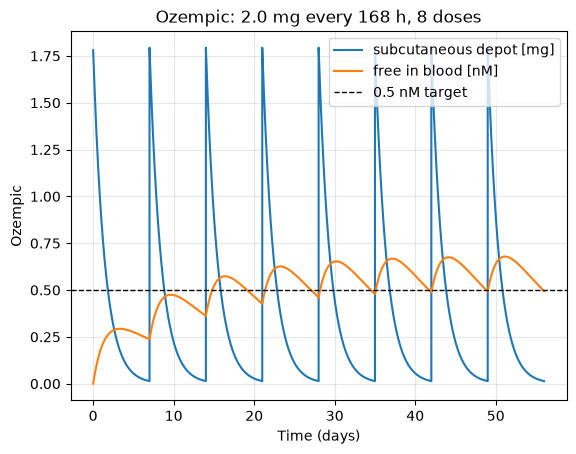

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product =====
drug = 'Ozempic'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 (see estimate below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
Mw = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()              # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc
ss = Cfree[t >= t[-1] - interval].mean()
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/MW*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Cfree, label="free in blood [nM]")
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')
plt.xlabel("Time (days)")
plt.ylabel(drug)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Wegovy: mean free concentration over last interval = 0.599 nM
Wegovy: analytical steady-state estimate = 0.601 nM


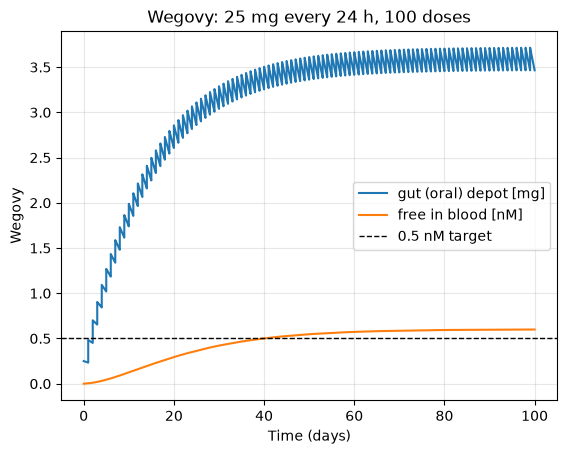

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product =====
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 (see estimate below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
Mw = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()              # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# ---steady-state check---
Cfree = Ffree*Cc
ss = Cfree[t >= t[-1] - interval].mean()
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/MW*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Cfree, label="free in blood [nM]")
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')
plt.xlabel("Time (days)")
plt.ylabel(drug)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Cavalitide: mean free concentration over last interval = 0.601 nM
Cavalitide: analytical steady-state estimate = 0.601 nM


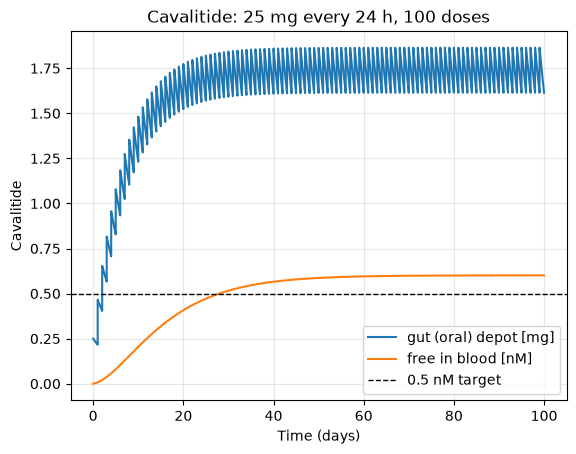

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product =====
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    # Part 2: ka from the assignment; Favailable, D, interval, n_doses ASSUMED same as Wegovy
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Part 3: same drug, adjusted dose (D) to reach ~0.5 nM free at steady state
    'CavalitideOpt': dict(Favailable=0.01,
                          ka=0.006,
                          D=21,            # mg, lowered from 25 (see estimate below)
                          interval=24,
                          n_doses=100,
                          depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
Mw = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# output grid spacing (no longer an Euler step size; solve_ivp picks its own internal steps)
dt = 0.1        # h

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # output points per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method='LSODA', rtol=1e-8, atol=1e-10)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()              # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- steady-state check: mean free concentration over the last dosing interval ---
Cfree = Ffree*Cc
ss = Cfree[t >= t[-1] - interval].mean()
print(f"{drug}: mean free concentration over last interval = {ss:.3f} nM")

# Analytical estimate (independent of ka): mean total conc = Favailable*D/(interval*V*ke) mg/L
ss_est = Ffree * (Favailable*D/(interval*V*ke)) * 1e-3/MW*1e9
print(f"{drug}: analytical steady-state estimate = {ss_est:.3f} nM")

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Cfree, label="free in blood [nM]")
plt.axhline(0.5, ls='--', c='k', lw=1, label='0.5 nM target')
plt.xlabel("Time (days)")
plt.ylabel(drug)
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

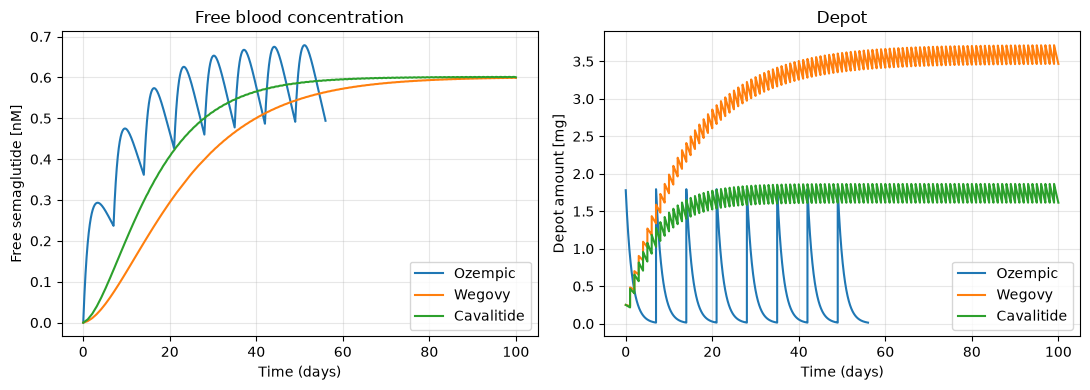

In [13]:
results = {}
for drug in ['Ozempic', 'Wegovy', 'Cavalitide']:
    products = {
        'Ozempic': dict(Favailable=0.89, ka=0.029, D=2.0, interval=168, n_doses=8, depot='subcutaneous'),
        'Wegovy': dict(Favailable=0.01, ka=0.0029, D=25, interval=24, n_doses=100, depot='gut (oral)'),
        'Cavalitide': dict(Favailable=0.01, ka=0.006, D=25, interval=24, n_doses=100, depot='gut (oral)')
    }
    p = products[drug]
    Favailable, ka, D = p['Favailable'], p['ka'], p['D']
    interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']
    t, Asc, Cc = simulate(D, n_doses, interval, dt)
    results[drug] = (t, Asc, Ffree*Cc)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for drug, (t, Asc, Cfree) in results.items():
    ax[0].plot(t/24, Cfree, label=drug)
    ax[1].plot(t/24, Asc, label=drug)
ax[0].set(xlabel="Time (days)", ylabel="Free semaglutide [nM]", title="Free blood concentration")
ax[1].set(xlabel="Time (days)", ylabel="Depot amount [mg]", title="Depot")
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.

Phase 1: D = 20.80 mg | free = 0.500 nM | Fact = 0.868
Free Cavalitide needed for 90% active: 0.686 nM -> D_opt = 28.54 mg
Phase 2 (optimized): D = 28.54 mg | free = 0.686 nM | Fact = 0.900


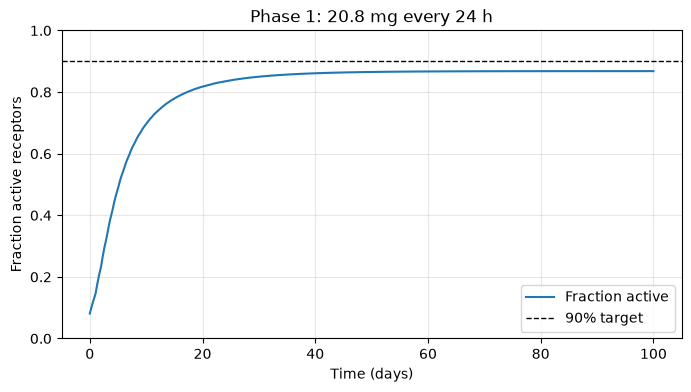

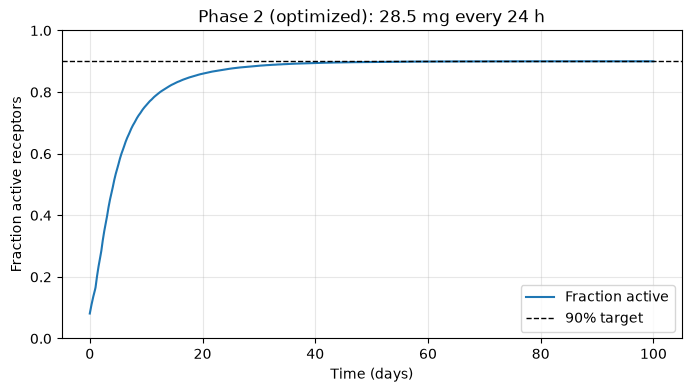

In [7]:
# cavalitidePKPD.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- PD parameters ----------
Kd1 = 0.17     # nM, GLP1
Kd2 = 0.077    # nM, Cavalitide (fitted in Task 1; was 0.38 = semaglutide)
L1 = 0.015     # nM, GLP1 (fasting)

# ---------- PK parameters ----------
Favailable = 0.01
ka = 0.006          # 1/h
interval = 24       # h
n_doses = 100
dt = 0.1            # h
ke = 0.0039
V = 10.8
MW = 4113.6         # g/mol
Ffree = 0.01

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc
    dCc = ka*Asc/V - ke*Cc
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Return time (h), depot amount (mg), and total blood concentration (nM)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        method="LSODA", rtol=1e-8, atol=1e-10)
        if not sol.success:
            raise RuntimeError(sol.message)
        t_out.append(sol.t); Asc_out.append(sol.y[0]); Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()
    t = np.concatenate(t_out)
    Asc = np.concatenate(Asc_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / MW * 1e9
    return t, Asc, Cc_nM

def run_and_plot(D, title):
    """Simulate one dose, embed PD model, print steady state, make one figure."""
    t, Asc, Cc = simulate(D, n_doses, interval, dt)
    Cfree = Ffree * Cc                    # free Cavalitide [nM] = L2
    Fa = Fact(L1, Cfree, Kd1, Kd2)        # PK output feeds the PD model
    last = t >= t[-1] - interval
    print(f"{title}: D = {D:.2f} mg | free = {Cfree[last].mean():.3f} nM | "
          f"Fact = {Fa[last].mean():.3f}")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t / 24, Fa, label="Fraction active")
    ax.axhline(0.9, ls="--", c="k", lw=1, label="90% target")
    ax.set(xlabel="Time (days)", ylabel="Fraction active receptors",
           title=f"{title}: {D:.1f} mg every {interval} h", ylim=(0, 1))
    ax.legend(); ax.grid(alpha=0.3)
    return Cfree[last].mean()

# ---------- Image 1: Phase 1 dose (0.5 nM) ----------
D_reference = 20.8
ref_mean = run_and_plot(D_reference, "Phase 1")

# ---------- dose needed for 90% active ----------
f_target = 0.90
L2_needed = (f_target*Kd2*(Kd1 + L1) - Kd2*L1) / (Kd1*(1 - f_target))  # nM free
D_opt = D_reference * L2_needed / ref_mean      # steady-state conc scales linearly with dose
print(f"Free Cavalitide needed for 90% active: {L2_needed:.3f} nM -> D_opt = {D_opt:.2f} mg")

# ---------- Image 2: optimized Phase 2 dose ----------
run_and_plot(D_opt, "Phase 2 (optimized)")

plt.show() 

Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.

- For this task, we adjusted the dose per pill from about 20.8 mg to about 28.5 mg a day. The dosing interval was kept at 24 hours, and Favailable and ka were unchanged. Steady-state drug concentration scales linearly with the dose, while receptor activation saturates. Because of this, we solved the binding equation for the free Cavalitide concentration that gives 90% activation (about 0.69 nM). Then, using that, we scaled the dose to reach it.
- From this, we can interpret that a 37% higher dose raises receptor activation by about 3 percentage points (from 86.8% to 90%). This cuts the inactive receptors from about 13% to 10%. Clinically, the higher dose could mean stronger appetite suppression and more weight loss. Phase 2 is the correct setting to test this, because it focuses on efficacy. However, the gain is small relative to the dose increase, so the benefit must be weighed against side effects such as nausea and the higher cost of a larger pill.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*

- We used Claude (Anthropic) to help fix errors and write the solve_ivp PK code, fit the Cavalitide Kd, and calculate the doses for Tasks 2 and 3. We verified that assumption and checked the results against the analytical steady-state formula.
- Claude was used to suggest changes to the disease background section to get it down to 200 words.
- Claude was used to find published studies to reference in the limitations section that included real pharmokinetic data, as it was difficult to find studies with the necessary data by manually searching.
- Claude was used to format in text citations and the references section. 

## GitHub Repository Link:
*https://github.com/KartikeyaV/BME-2315-Module-3*


## References:

1. NCHS, CDC. Obesity and Overweight Prevalence in Adults, August 2021–August 2023. https://www.cdc.gov/nchs/data/hestat/hestat111.htm
2. World Health Organization. Obesity and overweight fact sheet. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
3. Lecture 1, slides 12–13 (J Diabetes Investig 2010;1(1-2):8–23); Tschöp et al., Diabetologia 2023. https://pubmed.ncbi.nlm.nih.gov/37209227/
4. Lecture 1, slide 17; Brandt et al., Peptides 2018. https://www.sciencedirect.com/science/article/pii/S0196978117303960
5. Wilding et al., N Engl J Med 2021;384:989–1002 (STEP 1). https://pubmed.ncbi.nlm.nih.gov/33567185/
6. Applied Clinical Trials. FDA Approves Oral Wegovy (Dec 2025). https://appliedclinicaltrialsonline.com/view/fda-approves-oral-wegovy-positive-oasis-trial-results
7. Wilding et al., Weight regain and cardiometabolic effects after withdrawal of semaglutide: the STEP 1 trial extension. Diabetes Obes Metab 2022. https://pmc.ncbi.nlm.nih.gov/articles/PMC9542252/ (PubMed backup: https://pubmed.ncbi.nlm.nih.gov/35441470/)
8. Discontinuation of glucagon-like peptide-1 receptor agonists among US adults: A national survey. J Manag Care Spec Pharm 2026;32(8):903. https://doi.org/10.18553/jmcp.2026.32.8.903
9. Jastreboff et al., Retatrutide, a triple hormone receptor agonist, in adults with obesity (TRIUMPH-1). N Engl J Med 2026. https://doi.org/10.1056/NEJMoa2604169
10. AJMC. Weight-Loss Drug Maridebart Cafraglutide Shows Efficacy in Phase 2 Trial (1 Jul 2025). https://www.ajmc.com/view/weight-loss-drug-maridebart-cafraglutide-shows-efficacy-in-phase-2-trial